## In this notebook, we will combine the practice and information we have gathered during our examination on the EU 2024 FR dataset. 

### We will follow the structure for our final model below:

## Data Preparation and Modeling Workflow

```text
2024 FR raw
│
├── Common cleaning / feature engineering
│
└── 2024 train-validation split
    │
    ├── Train-only fit
    │   ├── Top brands
    │   ├── Frequency maps
    │   ├── Target encoder
    │   ├── Scaler
    │   └── Model
    │
    └── Validation transform only


2025 FR raw
│
└── Common cleaning / feature engineering
    │
    └── Transform only with the artefacts learnt in Train
        │
        └── Final test
```

# Import files

In [12]:
# human-readable display settings for pandas
import pandas as pd
import joblib

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)


df_2024_FR_cleaned_final = pd.read_csv("../data/processed/EU/2024_FR_cleaned_final.csv")
df_2025_FR_cleaned_final = pd.read_csv("../data/processed/EU/2025_FR_cleaned_final.csv")

print("2024 FR Cleaned Final:", df_2024_FR_cleaned_final.shape)
print("2025 FR Cleaned Final:", df_2025_FR_cleaned_final.shape)

2024 FR Cleaned Final: (113868, 22)
2025 FR Cleaned Final: (88963, 23)


# Data Split

In [13]:
# We split the 2024 FR cleaned final dataset into training and validation sets based on group columns.
from sklearn.model_selection import GroupShuffleSplit

group_columns = [
    "VFN",
    "Tan",
    "T",
    "Va",
    "Ve",
    "Mk",
    "Cn",
    "Ct",
    "m (kg)",
    "Mt",
    "Ft",
    "Fm",
    "ec (cm3)",
    "ep (KW)",
    "z (Wh/km)",
    "IT",
    "Electric range (km)",
]

group_columns = [
    col for col in group_columns
    if col in df_2024_FR_cleaned_final.columns
]

group_id_2024 = (
    df_2024_FR_cleaned_final
    .groupby(group_columns, dropna=False)
    .ngroup()
)

# Divide Target and Features
TARGET = "Ewltp (g/km)"
y_2024 = df_2024_FR_cleaned_final[TARGET].copy()

X_2024 = df_2024_FR_cleaned_final.drop(
    columns=[TARGET],
    errors="ignore"
).copy()

# Split
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, val_idx = next(
    gss.split(
        X_2024,
        y_2024,
        groups=group_id_2024,
    )
)

X_train = X_2024.iloc[train_idx].copy()
X_val = X_2024.iloc[val_idx].copy()

y_train = y_2024.iloc[train_idx].copy()
y_val = y_2024.iloc[val_idx].copy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)

# Control
train_groups = set(group_id_2024.iloc[train_idx])
val_groups = set(group_id_2024.iloc[val_idx])

assert train_groups.isdisjoint(val_groups)

Train: (91084, 21)
Validation: (22784, 21)


# Prepare the test set

In [14]:
# Divide target and features for the 2025 FR cleaned final dataset
y_test = df_2025_FR_cleaned_final[TARGET].copy()

X_test = df_2025_FR_cleaned_final.drop(
    columns=[TARGET],
    errors="ignore"
).copy()

# Control
print(TARGET in df_2025_FR_cleaned_final.columns)
print(df_2025_FR_cleaned_final[TARGET].isna().sum())

True
0


# Apply Make grouping

In [15]:
# Make grouping should be learned solely from the training set
top_makes = (
    X_train["Mk"]
    .value_counts()
    .nlargest(30)
    .index
)

for frame in [X_train, X_val, X_test]:
    frame["Make_Grouped"] = frame["Mk"].where(
        frame["Mk"].isin(top_makes),
        "OTHER"
    )

# At this point:
    # New labels in validation are set to "OTHER."
    # New labels in 2025 are set to "OTHER."
    # The 2025 distribution does not affect train preprocessing.

# Apply Target encoding for Make_Grouped

In [16]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import TargetEncoder

from sklearn import set_config
set_config(enable_metadata_routing=True)

# Derive the group ID only on the train
train_groups_series = (
    X_train
    .groupby(group_columns, dropna=False)
    .ngroup()
)

train_group_ids = train_groups_series.to_numpy()

# Group-aware TargetEncoder
target_encoder_cv = GroupKFold(n_splits=5)

make_target_encoder = TargetEncoder(
    smooth="auto",
    target_type="continuous",
    cv=target_encoder_cv,
)

# Train - fit_transform (with group awareness)
X_train_make_encoded = make_target_encoder.fit_transform(
    X_train[["Make_Grouped"]],
    y_train,
    groups=train_group_ids,
)

X_train["Make_Encoded"] = X_train_make_encoded[:, 0]

# Validation - transform only
X_val_make_encoded = make_target_encoder.transform(
    X_val[["Make_Grouped"]]
)
X_val["Make_Encoded"] = X_val_make_encoded[:, 0]

# 2025 test - transform only
X_test_make_encoded = make_target_encoder.transform(
    X_test[["Make_Grouped"]]
)
X_test["Make_Encoded"] = X_test_make_encoded[:, 0]

# Drop Raw Categoricals 
drop_cols = ["Mk", "Make_Grouped"]
X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_val = X_val.drop(columns=drop_cols, errors="ignore")
X_test = X_test.drop(columns=drop_cols, errors="ignore")

# Perform frequency encoding based on the training data

In [17]:
def add_frequency_feature(
    train_frame,
    other_frames,
    source_column,
    output_column,
):
    frequency_map = (
        train_frame[source_column]
        .value_counts(dropna=False)
    )

    train_frame[output_column] = (
        train_frame[source_column]
        .map(frequency_map)
        .fillna(0)
        .astype("int32")
    )

    for frame in other_frames:
        frame[output_column] = (
            frame[source_column]
            .map(frequency_map)
            .fillna(0)
            .astype("int32")
        )

    return train_frame, other_frames

frequency_columns = {
    "Cn": "Model_Frequency",
    "VFN": "VFN_Frequency",
    "Tan": "Tan_Frequency",
    "T": "T_Frequency",
    "Va": "Va_Frequency",
    "Ve": "Ve_Frequency",
    "Ct": "Ct_Frequency",
    "RLFI": "RLFI_Frequency",
}

for source_column, output_column in frequency_columns.items():
    if source_column not in X_train.columns:
        continue

    X_train, [X_val, X_test] = add_frequency_feature(
        train_frame=X_train,
        other_frames=[X_val, X_test],
        source_column=source_column,
        output_column=output_column,
    )

# Drop the original categorical columns after adding frequency features
for column in frequency_columns.keys():
    if column in X_train.columns:
        X_train.drop(columns=column, inplace=True)
        X_val.drop(columns=column, inplace=True)
        X_test.drop(columns=column, inplace=True)
    
# Important: In 2025, a category that was never seen in the training data will have a frequency of 0. This is expected behavior.

# Implement IT encoding in a shared and leakage-free manner

In [18]:
# Since no target information is used for IT, the same function can be applied to all sets
import re

IT_CODES = ["28", "29", "32", "33", "37", "38", "none"]


def extract_it_tokens(value):
    return re.findall(
        r"\b\d+\b|\bnone\b",
        str(value).lower(),
    )


def encode_it_columns(frame, it_column="IT"):
    frame = frame.copy()

    it_tokens = frame[it_column].map(
        extract_it_tokens
    )

    for code in IT_CODES:
        frame[f"IT_{code}"] = (
            it_tokens
            .map(lambda tokens: int(code in tokens))
            .astype("int8")
        )

    return frame.drop(
        columns=[it_column],
        errors="ignore"
    )

X_train = encode_it_columns(X_train)
X_val = encode_it_columns(X_val)
X_test = encode_it_columns(X_test)

# Ft, Fm One-Hot Encoding

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import pandas as pd
import re

onehot_columns = ["Ft", "Fm"]

fuel_onehot_pipeline = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("fuel_onehot", fuel_onehot_pipeline, onehot_columns),
    ],
    remainder="passthrough",
    sparse_threshold=0,
)

# Fit and transform
X_train_encoded_array = preprocessor.fit_transform(X_train)
X_val_encoded_array   = preprocessor.transform(X_val)
X_test_encoded_array  = preprocessor.transform(X_test)

# Get all column names and remove prefixes
raw_columns = preprocessor.get_feature_names_out()

def clean_column_name(name: str) -> str:
    """Remove 'fuel_onehot__' and 'remainder__' prefixes"""
    return re.sub(r"^(fuel_onehot|remainder)__", "", name)

all_columns = [clean_column_name(col) for col in raw_columns]

# Convert to DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded_array,
    columns=all_columns,
    index=X_train.index,
)

X_val_encoded = pd.DataFrame(
    X_val_encoded_array,
    columns=all_columns,
    index=X_val.index,
)

X_test_encoded = pd.DataFrame(
    X_test_encoded_array,
    columns=all_columns,
    index=X_test.index,
)

In [20]:
from pathlib import Path

split_dir = Path("../data/processed/eu/splits/final")

# If the folder doesn't exist, create it; if it does exist, don't return an error
split_dir.mkdir(parents=True, exist_ok=True)

print(X_train_encoded.columns.to_list())
print(X_val_encoded.columns.to_list())
print(X_test_encoded.columns.to_list())

# save encoded split data
X_train_encoded.to_parquet(split_dir / "X_train_2024_encoded_final.parquet", index=True)
X_val_encoded.to_parquet(split_dir / "X_val_2024_encoded_final.parquet", index=True)
X_test_encoded.to_parquet(split_dir / "X_test_2025_encoded_final.parquet", index=True)

['Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'm (kg)', 'Mt', 'ec (cm3)', 'ep (KW)', 'z (Wh/km)', 'Erwltp (g/km)', 'Fuel consumption', 'Electric range (km)', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
['Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'm (kg)', 'Mt', 'ec (cm3)', 'ep (KW)', 'z (Wh/km)', 'Erwltp (g/km)', 'Fuel consumption', 'Electric range (km)', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
['Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'm (kg)', 'Mt', 'ec (cm3)', 'ep (KW)', 'z (Wh/km)',

# Scaling

In [10]:
from sklearn.preprocessing import StandardScaler

# Prepare Scaled Data (FOR LINEAR MODELS ONLY) ---
# Scale only the continuous numeric columns
numeric_cols = [
    "ec (cm3)",
    "ep (KW)",
    "m (kg)",
    "z (Wh/km)",
    "Electric range (km)",
    "Model_Frequency",
    "Make_Encoded",
    "VFN_Frequency",
    "Tan_Frequency",
    "T_Frequency",
    "Va_Frequency",
    "Ve_Frequency",
    "Ct_Frequency",
    "RLFI_Frequency",
]

# Retrieve only the existing columns (safety)
numeric_cols = [
    col for col in numeric_cols
    if col in X_train_encoded.columns
]

scaler = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_cols),
    ],
    remainder="passthrough",
)

# Fit and transform the training data
X_train_encoded_scaled_array = scaler.fit_transform(X_train_encoded)

# only transform the validation and test data
X_val_encoded_scaled_array = scaler.transform(X_val_encoded)
X_test_encoded_scaled_array = scaler.transform(X_test_encoded)

# Keep column names
scaled_cols = numeric_cols
remainder_cols = [
    col for col in X_train_encoded.columns
    if col not in numeric_cols
]
all_columns = scaled_cols + remainder_cols

# Convert to DataFrame
X_train_encoded_scaled = pd.DataFrame(
    X_train_encoded_scaled_array,
    columns=all_columns,
    index=X_train_encoded.index,
)

X_val_encoded_scaled = pd.DataFrame(
    X_val_encoded_scaled_array,
    columns=all_columns,
    index=X_val_encoded.index,
)

X_test_encoded_scaled = pd.DataFrame(
    X_test_encoded_scaled_array,
    columns=all_columns,
    index=X_test_encoded.index,
)

# -----------------------------------------------------
# 5) Checks
# -----------------------------------------------------

print("X_train_encoded_scaled shape:", X_train_encoded_scaled.shape)
print("X_train_encoded_scaled columns list:", X_train_encoded_scaled.columns.tolist())
print("X_train_encoded_scaled empty data:", X_train_encoded_scaled.isna().sum().sum())
print("X_train_encoded_scaled data types:", X_train_encoded_scaled.dtypes.value_counts())

# Print verification of scaled data (mean ≈ 0, std ≈ 1)
print("X_train_encoded_scaled scaled columns mean:\n", X_train_encoded_scaled[numeric_cols].mean().round(4))
print("\nX_train_encoded_scaled scaled columns std:\n", X_train_encoded_scaled[numeric_cols].std().round(4))
print("\n*********\n")

print("X_val_encoded_scaled shape:", X_val_encoded_scaled.shape)
print("X_val_encoded_scaled columns list:", X_val_encoded_scaled.columns.tolist())
print("X_val_encoded_scaled empty data:", X_val_encoded_scaled.isna().sum().sum())
print("X_val_encoded_scaled data types:", X_val_encoded_scaled.dtypes.value_counts())
print("\n*********\n")

print("X_test_encoded_scaled shape:", X_test_encoded_scaled.shape)
print("X_test_encoded_scaled columns list:", X_test_encoded_scaled.columns.tolist())
print("X_test_encoded_scaled empty data:", X_test_encoded_scaled.isna().sum().sum())
print("X_test_encoded_scaled data types:", X_test_encoded_scaled.dtypes.value_counts())

# Check column alignment
assert list(X_train_encoded_scaled.columns) == list(X_val_encoded_scaled.columns)
assert list(X_train_encoded_scaled.columns) == list(X_test_encoded_scaled.columns)

X_train_encoded_scaled shape: (91084, 32)
X_train_encoded_scaled columns list: ['ec (cm3)', 'ep (KW)', 'm (kg)', 'z (Wh/km)', 'Electric range (km)', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'Mt', 'Erwltp (g/km)', 'Fuel consumption', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
X_train_encoded_scaled empty data: 0
X_train_encoded_scaled data types: float64    32
Name: count, dtype: int64
X_train_encoded_scaled scaled columns mean:
 ec (cm3)               0.0000
ep (KW)                0.0000
m (kg)                -0.0000
z (Wh/km)              0.0000
Electric range (km)    0.0000
Model_Frequency       -0.0000
Make_Encoded           0.0000
VFN_Frequency         -0.0000
Tan_Frequency          0.0000
T_Frequency           -0.0000
Va_Frequency          -0.0000
Ve_Freq

In [ ]:

# save encoded split data
X_train_encoded.to_parquet(split_dir / "X_train_encoded_final.parquet", index=True)
X_val_encoded.to_parquet(split_dir / "X_val_encoded_final.parquet", index=True)
X_test_encoded.to_parquet(split_dir / "X_test_encoded_final.parquet", index=True)

# save encoded and scaled split data
X_train_encoded_scaled.to_parquet(split_dir / "X_train_encoded_scaled_final.parquet", index=True)
X_val_encoded_scaled.to_parquet(split_dir / "X_val_encoded_scaled_final.parquet", index=True)
X_test_encoded_scaled.to_parquet(split_dir / "X_test_encoded_scaled_final.parquet", index=True)

y_train.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train.parquet", index=True)
y_val.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_val.parquet", index=True)
y_test.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test.parquet", index=True)


# control
print("******")
print("X_train_encoded saved:", (split_dir / "X_train_encoded_final.parquet").exists())
print("X_val_encoded saved:", (split_dir / "X_val_encoded_final.parquet").exists())
print("X_test_encoded saved:", (split_dir / "X_test_encoded_final.parquet").exists())
print("******")
print("X_train_encoded_scaled saved:", (split_dir / "X_train_encoded_scaled_final.parquet").exists())
print("X_val_encoded_scaled saved:", (split_dir / "X_val_encoded_scaled_final.parquet").exists())
print("X_test_encoded_scaled saved:", (split_dir / "X_test_encoded_scaled_final.parquet").exists())
print("******")
print("y_train saved:", (split_dir / "y_train.parquet").exists())
print("y_val saved:", (split_dir / "y_val.parquet").exists())
print("y_test saved:", (split_dir / "y_test.parquet").exists())


joblib.dump(scaler, split_dir / "complete_scaler.joblib")

******
X_train_encoded saved: True
X_val_encoded saved: True
X_test_encoded saved: True
******
X_train_encoded_scaled saved: True
X_val_encoded_scaled saved: True
X_test_encoded_scaled saved: True
******
y_train saved: True
y_val saved: True
y_test saved: True


['../data/processed/eu/splits/final/complete_scaler.joblib']

In [12]:
from lazypredict.Supervised import REGRESSORS
from lazypredict import LazyRegressor

# Exclude some troublesome regressors
safe_regressors = [
    cls
    for name, cls in REGRESSORS
    if ((name != "GaussianProcessRegressor") and (name != "KernelRidge") and (name != "NuSVR") and (name != "QuantileRegressor") and (name != "SVR"))
]

print("Total number of available regressors:", len(REGRESSORS))
print("\nList of safe regressors:\n", [cls.__name__ for cls in safe_regressors])


# Wrap each regressor so we can see which model is currently running
def make_verbose_regressor(cls):
    class VerboseRegressor(cls):
        def fit(self, X, y, *args, **kwargs):
            print(f"\n>>> STARTING: {cls.__name__}", flush=True)
            result = super().fit(X, y, *args, **kwargs)
            print(f">>> FINISHED: {cls.__name__}", flush=True)
            return result

    VerboseRegressor.__name__ = cls.__name__
    VerboseRegressor.__qualname__ = cls.__qualname__

    return VerboseRegressor


verbose_regressors = [
    make_verbose_regressor(cls)
    for cls in safe_regressors
]


reg = LazyRegressor(
    verbose=1,
    ignore_warnings=True,
    regressors=verbose_regressors,
)

models, predictions = reg.fit(
    X_train_encoded_scaled,
    X_val_encoded_scaled,
    y_train,
    y_val,
)

models

Total number of available regressors: 41

List of safe regressors:
 ['AdaBoostRegressor', 'BaggingRegressor', 'BayesianRidge', 'DecisionTreeRegressor', 'DummyRegressor', 'ElasticNet', 'ElasticNetCV', 'ExtraTreeRegressor', 'ExtraTreesRegressor', 'GammaRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor', 'HuberRegressor', 'KNeighborsRegressor', 'Lars', 'LarsCV', 'Lasso', 'LassoCV', 'LassoLars', 'LassoLarsCV', 'LassoLarsIC', 'LinearRegression', 'LinearSVR', 'MLPRegressor', 'OrthogonalMatchingPursuit', 'OrthogonalMatchingPursuitCV', 'PassiveAggressiveRegressor', 'PoissonRegressor', 'RANSACRegressor', 'RandomForestRegressor', 'Ridge', 'RidgeCV', 'SGDRegressor', 'TransformedTargetRegressor', 'TweedieRegressor', 'LGBMRegressor']


  0%|          | 0/36 [00:00<?, ?it/s]


>>> STARTING: AdaBoostRegressor
>>> FINISHED: AdaBoostRegressor

>>> STARTING: BaggingRegressor
>>> FINISHED: BaggingRegressor

>>> STARTING: BayesianRidge
>>> FINISHED: BayesianRidge

>>> STARTING: DecisionTreeRegressor
>>> FINISHED: DecisionTreeRegressor

>>> STARTING: DummyRegressor
>>> FINISHED: DummyRegressor

>>> STARTING: ElasticNet
>>> FINISHED: ElasticNet

>>> STARTING: ElasticNetCV

>>> STARTING: ExtraTreeRegressor
>>> FINISHED: ExtraTreeRegressor

>>> STARTING: ExtraTreesRegressor
>>> FINISHED: ExtraTreesRegressor

>>> STARTING: GammaRegressor
>>> FINISHED: GammaRegressor

>>> STARTING: GradientBoostingRegressor
>>> FINISHED: GradientBoostingRegressor

>>> STARTING: HistGradientBoostingRegressor
>>> FINISHED: HistGradientBoostingRegressor

>>> STARTING: HuberRegressor
>>> FINISHED: HuberRegressor

>>> STARTING: KNeighborsRegressor
>>> FINISHED: KNeighborsRegressor

>>> STARTING: Lars
>>> FINISHED: Lars

>>> STARTING: LarsCV
>>> FINISHED: LarsCV

>>> STARTING: Lasso
>>> FINI

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
ExtraTreesRegressor,0.9999,0.9999,0.5061,14.6171
RandomForestRegressor,0.9999,0.9999,0.5283,27.9909
BaggingRegressor,0.9999,0.9999,0.5439,4.2654
DecisionTreeRegressor,0.9999,0.9999,0.6384,0.4562
MLPRegressor,0.9998,0.9998,0.8328,15.7411
LGBMRegressor,0.9997,0.9997,0.9517,0.9058
HistGradientBoostingRegressor,0.9997,0.9997,0.9727,1.2000
ExtraTreeRegressor,0.9997,0.9997,1.0540,0.1801
GradientBoostingRegressor,0.9994,0.9994,1.3591,11.4512


In [13]:
best_model_name = models.iloc[0].name

best_model_cls = next(
    cls
    for name, cls in REGRESSORS
    if cls.__name__ == best_model_name
)

best_model = best_model_cls()

print("Best model name:", best_model_name)
print("Best model class:", best_model_cls)
print("Best model instance:", best_model)


Best model name: ExtraTreesRegressor
Best model class: <class 'sklearn.ensemble._forest.ExtraTreesRegressor'>
Best model instance: ExtraTreesRegressor()


In [14]:
best_model.fit(X_train_encoded_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, 

In [15]:
# final test
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred_2025 = best_model.predict(X_test_encoded_scaled)

test_mae = mean_absolute_error(y_test, y_pred_2025)
test_rmse = root_mean_squared_error(y_test, y_pred_2025)
test_r2 = r2_score(y_test, y_pred_2025)

print("2025 Test MAE:", test_mae)
print("2025 Test RMSE:", test_rmse)
print("2025 Test R2:", test_r2)
print("*****")
y_pred_val = best_model.predict(X_val_encoded_scaled)

val_mae = mean_absolute_error(y_val, y_pred_val)
val_rmse = root_mean_squared_error(y_val, y_pred_val)
val_r2 = r2_score(y_val, y_pred_val)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)

2025 Test MAE: 1.6847399478369511
2025 Test RMSE: 5.135727153342406
2025 Test R2: 0.9903073252858163
*****
Validation MAE: 0.20802269705795312
Validation RMSE: 0.5145706002368251
Validation R2: 0.9999181753557116


# Let's check our leakage suspects now:

In [16]:
# Those were our suspects from the data exploration phase:
leakage_candidates = [
    "Fuel consumption",
    "Erwltp (g/km)",
    "z (Wh/km)",
    "Mt"
]

In [17]:
best_model.fit(X_train_encoded_scaled.drop(["Fuel consumption"], axis=1), y_train)
# final test
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred_2025 = best_model.predict(X_test_encoded_scaled.drop(["Fuel consumption"], axis=1))

test_mae = mean_absolute_error(y_test, y_pred_2025)
test_rmse = root_mean_squared_error(y_test, y_pred_2025)
test_r2 = r2_score(y_test, y_pred_2025)

print("2025 Test MAE:", test_mae)
print("2025 Test RMSE:", test_rmse)
print("2025 Test R2:", test_r2)
print("*****")
y_pred_val = best_model.predict(X_val_encoded_scaled.drop(["Fuel consumption"], axis=1))

val_mae = mean_absolute_error(y_val, y_pred_val)
val_rmse = root_mean_squared_error(y_val, y_pred_val)
val_r2 = r2_score(y_val, y_pred_val)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)

2025 Test MAE: 4.324726191285391
2025 Test RMSE: 10.890998019571759
2025 Test R2: 0.9564111801784799
*****
Validation MAE: 0.5116437216618529
Validation RMSE: 1.2012025207157622
Validation R2: 0.9995541111041609


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |

In [18]:
best_model.fit(X_train_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)"], axis=1), y_train)
# final test
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred_2025 = best_model.predict(X_test_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)"], axis=1))

test_mae = mean_absolute_error(y_test, y_pred_2025)
test_rmse = root_mean_squared_error(y_test, y_pred_2025)
test_r2 = r2_score(y_test, y_pred_2025)

print("2025 Test MAE:", test_mae)
print("2025 Test RMSE:", test_rmse)
print("2025 Test R2:", test_r2)
print("*****")
y_pred_val = best_model.predict(X_val_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)"], axis=1))

val_mae = mean_absolute_error(y_val, y_pred_val)
val_rmse = root_mean_squared_error(y_val, y_pred_val)
val_r2 = r2_score(y_val, y_pred_val)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)

2025 Test MAE: 4.287167165541692
2025 Test RMSE: 10.884342483232304
2025 Test R2: 0.9564644385356988
*****
Validation MAE: 0.518202704973253
Validation RMSE: 1.2238565636697207
Validation R2: 0.9995371340540259


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" | Validation MAE: 0.5182<br>Validation RMSE: 1.2239<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2872<br>2025 Test RMSE: 10.8843<br>2025 Test R²: 0.9564 |

In [19]:
best_model.fit(X_train_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)"], axis=1), y_train)
# final test
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred_2025 = best_model.predict(X_test_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)"], axis=1))

test_mae = mean_absolute_error(y_test, y_pred_2025)
test_rmse = root_mean_squared_error(y_test, y_pred_2025)
test_r2 = r2_score(y_test, y_pred_2025)

print("2025 Test MAE:", test_mae)
print("2025 Test RMSE:", test_rmse)
print("2025 Test R2:", test_r2)
print("*****")
y_pred_val = best_model.predict(X_val_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)"], axis=1))

val_mae = mean_absolute_error(y_val, y_pred_val)
val_rmse = root_mean_squared_error(y_val, y_pred_val)
val_r2 = r2_score(y_val, y_pred_val)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)

2025 Test MAE: 4.2758514279832704
2025 Test RMSE: 10.73522024489745
2025 Test R2: 0.9576491949591821
*****
Validation MAE: 0.5340806142366058
Validation RMSE: 1.2144663305677998
Validation R2: 0.9995442096296481


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" | Validation MAE: 0.5182<br>Validation RMSE: 1.2239<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2872<br>2025 Test RMSE: 10.8843<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" | Validation MAE: 0.5341<br>Validation RMSE: 1.2145<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2759<br>2025 Test RMSE: 10.7352<br>2025 Test R²: 0.9576 |

In [20]:
best_model.fit(X_train_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt"], axis=1), y_train)
# final test
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred_2025 = best_model.predict(X_test_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt"], axis=1))

test_mae = mean_absolute_error(y_test, y_pred_2025)
test_rmse = root_mean_squared_error(y_test, y_pred_2025)
test_r2 = r2_score(y_test, y_pred_2025)

print("2025 Test MAE:", test_mae)
print("2025 Test RMSE:", test_rmse)
print("2025 Test R2:", test_r2)
print("*****")
y_pred_val = best_model.predict(X_val_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt"], axis=1))

val_mae = mean_absolute_error(y_val, y_pred_val)
val_rmse = root_mean_squared_error(y_val, y_pred_val)
val_r2 = r2_score(y_val, y_pred_val)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)

2025 Test MAE: 4.542624753060185
2025 Test RMSE: 10.7986188684013
2025 Test R2: 0.9571474984894547
*****
Validation MAE: 0.8459156579334075
Validation RMSE: 1.6156075256663336
Validation R2: 0.9991933856904059


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" | Validation MAE: 0.5182<br>Validation RMSE: 1.2239<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2872<br>2025 Test RMSE: 10.8843<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" | Validation MAE: 0.5341<br>Validation RMSE: 1.2145<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2759<br>2025 Test RMSE: 10.7352<br>2025 Test R²: 0.9576 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" | Validation MAE: 0.8459<br>Validation RMSE: 1.6156<br>Validation R²: 0.9992 | 2025 Test MAE: 4.5426<br>2025 Test RMSE: 10.7986<br>2025 Test R²: 0.9571 |

In [21]:
best_model.fit(X_train_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt", "Make_Encoded"], axis=1), y_train)
# final test
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_pred_2025 = best_model.predict(X_test_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt", "Make_Encoded"], axis=1))

test_mae = mean_absolute_error(y_test, y_pred_2025)
test_rmse = root_mean_squared_error(y_test, y_pred_2025)
test_r2 = r2_score(y_test, y_pred_2025)

print("2025 Test MAE:", test_mae)
print("2025 Test RMSE:", test_rmse)
print("2025 Test R2:", test_r2)
print("*****")
y_pred_val = best_model.predict(X_val_encoded_scaled.drop(["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt", "Make_Encoded"], axis=1))

val_mae = mean_absolute_error(y_val, y_pred_val)
val_rmse = root_mean_squared_error(y_val, y_pred_val)
val_r2 = r2_score(y_val, y_pred_val)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)
print("Validation R2:", val_r2)

2025 Test MAE: 4.6409003606641726
2025 Test RMSE: 10.919121263047339
2025 Test R2: 0.9561857753578006
*****
Validation MAE: 0.8247630123529289
Validation RMSE: 1.592516737571277
Validation R2: 0.9992162777108404


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" | Validation MAE: 0.5182<br>Validation RMSE: 1.2239<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2872<br>2025 Test RMSE: 10.8843<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" | Validation MAE: 0.5341<br>Validation RMSE: 1.2145<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2759<br>2025 Test RMSE: 10.7352<br>2025 Test R²: 0.9576 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" | Validation MAE: 0.8459<br>Validation RMSE: 1.6156<br>Validation R²: 0.9992 | 2025 Test MAE: 4.5426<br>2025 Test RMSE: 10.7986<br>2025 Test R²: 0.9571 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" <br>-"Make_Encoded" | Validation MAE: 0.8248<br>Validation RMSE: 1.5925<br>Validation R²: 0.9992 | 2025 Test MAE: 4.6409<br>2025 Test RMSE: 10.9191<br>2025 Test R²: 0.9562 |

# Let's try to drop the frequency columns and see the change:

In [22]:
# Drop the “Frequency” columns and the “Vehicle” column
freq_cols = [
    "Model_Frequency",
    "VFN_Frequency",
    "Tan_Frequency",
    "T_Frequency",
    "Va_Frequency",
    "Ve_Frequency",
    "Ct_Frequency",
    "RLFI_Frequency",
]

cols_to_drop = freq_cols + ["Fuel consumption", "Erwltp (g/km)", "z (Wh/km)", "Mt", "Make_Encoded"]

cols_without_freq = [
    c for c in X_train_encoded_scaled.columns
    if c not in cols_to_drop
]

best_model.fit(X_train_encoded_scaled[cols_without_freq], y_train)

y_pred_val = best_model.predict(X_val_encoded_scaled[cols_without_freq])
y_pred_2025 = best_model.predict(X_test_encoded_scaled[cols_without_freq])

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

print("2025 Test MAE:", mean_absolute_error(y_test, y_pred_2025))
print("2025 Test RMSE:", root_mean_squared_error(y_test, y_pred_2025))
print("2025 Test R2:", r2_score(y_test, y_pred_2025))
print("*****")
print("Validation MAE:", mean_absolute_error(y_val, y_pred_val))
print("Validation RMSE:", root_mean_squared_error(y_val, y_pred_val))
print("Validation R2:", r2_score(y_val, y_pred_val))



2025 Test MAE: 5.047924852581139
2025 Test RMSE: 11.150763498558712
2025 Test R2: 0.9543070747952184
*****
Validation MAE: 1.3789786357194365
Validation RMSE: 2.412135410315774
Validation R2: 0.9982019674247165


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" | Validation MAE: 0.5182<br>Validation RMSE: 1.2239<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2872<br>2025 Test RMSE: 10.8843<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" | Validation MAE: 0.5341<br>Validation RMSE: 1.2145<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2759<br>2025 Test RMSE: 10.7352<br>2025 Test R²: 0.9576 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" | Validation MAE: 0.8459<br>Validation RMSE: 1.6156<br>Validation R²: 0.9992 | 2025 Test MAE: 4.5426<br>2025 Test RMSE: 10.7986<br>2025 Test R²: 0.9571 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" <br>-"Make_Encoded" | Validation MAE: 0.8248<br>Validation RMSE: 1.5925<br>Validation R²: 0.9992 | 2025 Test MAE: 4.6409<br>2025 Test RMSE: 10.9191<br>2025 Test R²: 0.9562 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" <br>-"Make_Encoded" <br>-"Model_Frequency" <br>-"VFN_Frequency" <br>-"Tan_Frequency" <br>-"T_Frequency" <br>-"Va_Frequency" <br>-"Ve_Frequency" <br>-"Ct_Frequency" <br>-"RLFI_Frequency" | Validation MAE: 1.3790<br>Validation RMSE: 2.4121<br>Validation R²: 0.9982 | 2025 Test MAE: 5.0479<br>2025 Test RMSE: 11.1508<br>2025 Test R²: 0.9543 |

                feature  importance
10                 Fm_P      0.5785
3   Electric range (km)      0.2992
2                m (kg)      0.0397
1               ep (KW)      0.0388
0              ec (cm3)      0.0199
9                  Fm_M      0.0066
8                  Fm_H      0.0041
6             Ft_petrol      0.0026
4             Ft_diesel      0.0021
16                IT_37      0.0021
15                IT_33      0.0018
18              IT_none      0.0011
14                IT_32      0.0011
12                IT_28      0.0008
13                IT_29      0.0007
7    Ft_petrol/electric      0.0004
11                    r      0.0003
5    Ft_diesel/electric      0.0002
17                IT_38      0.0000


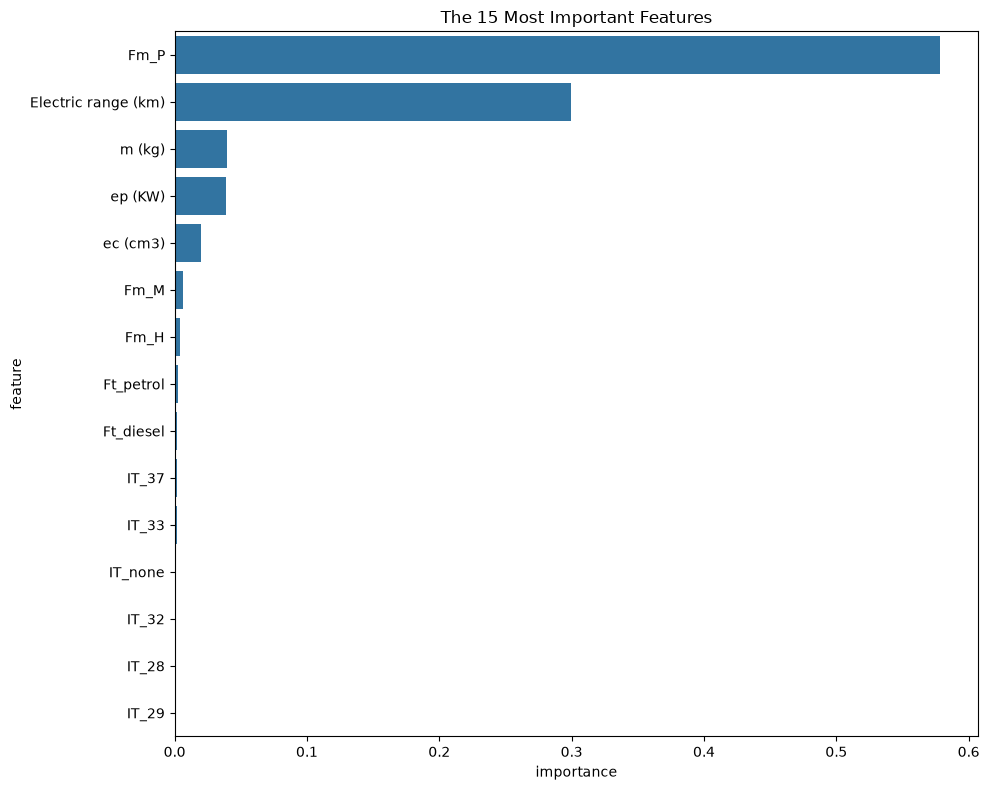

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Feature importance
fi = pd.DataFrame({
    "feature": cols_without_freq,
    "importance": best_model.feature_importances_
}).sort_values("importance", ascending=False)

print(fi)

# Visualize
plt.figure(figsize=(10, 8))
sns.barplot(data=fi.head(15), x="importance", y="feature", orient="h")
plt.title("The 15 Most Important Features")
plt.tight_layout()
plt.show()

## Feature Importance Analysis

This feature importance table is very interesting The top 3 features:

- `Fm_P` (PHEV - Plug-in Hybrid) → 0.36
- `Ft_petrol/electric` (Petrol/Electric hybrid) → 0.32
- `Electric range (km)` → 0.19

These three together account for ~0.87 importance. In other words, 87% of the model's decisions are based on these three features.

### Why Is This Suspicious?

Because our dataset contains only petrol, diesel, and petrol/electric vehicles (you previously excluded electric and hydrogen vehicles). This means:

- `Fm_P` (PHEV) and `Ft_petrol/electric` carry almost the same information.
- `Electric range (km)` shows the electric range of PHEV vehicles.

The model has learned the relationship "PHEV vehicles have low CO2 emissions." This is a correct relationship, but such dominance is suspicious.

### Possible Scenarios
- PHEV vehicles in the dataset have very low CO2 emissions → The model has learned this simple pattern.
- CO2 emissions from PHEV vehicles are nearly constant → The model has memorized the association "PHEV = low CO2."
- The "Electric range (km)" column is causing leakage → The range of PHEV vehicles may be directly related to CO2 emissions.

## Let's go one more step further and drop the top 3 and repeat the test:


In [24]:
cols_to_drop = cols_to_drop + ["Fm_P", "Ft_petrol/electric", "Electric range (km)"]

cols_without_freq = [
    c for c in X_train_encoded_scaled.columns
    if c not in cols_to_drop
]

best_model.fit(X_train_encoded_scaled[cols_without_freq], y_train)

y_pred_val = best_model.predict(X_val_encoded_scaled[cols_without_freq])
y_pred_2025 = best_model.predict(X_test_encoded_scaled[cols_without_freq])

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

print("2025 Test MAE:", mean_absolute_error(y_test, y_pred_2025))
print("2025 Test RMSE:", root_mean_squared_error(y_test, y_pred_2025))
print("2025 Test R2:", r2_score(y_test, y_pred_2025))
print("*****")
print("Validation MAE:", mean_absolute_error(y_val, y_pred_val))
print("Validation RMSE:", root_mean_squared_error(y_val, y_pred_val))
print("Validation R2:", r2_score(y_val, y_pred_val))

2025 Test MAE: 5.246860310604241
2025 Test RMSE: 10.867113279590491
2025 Test R2: 0.9566021573531706
*****
Validation MAE: 1.6832534590507449
Validation RMSE: 2.5983412292281196
Validation R2: 0.9979136529294708


| Fields | Val Results | Test Results |
|--------|-------------|--------------|
| All fields | Validation MAE: 0.2080<br>Validation RMSE: 0.5146<br>Validation R²: 0.9999 | 2025 Test MAE: 1.6847<br>2025 Test RMSE: 5.1357<br>2025 Test R²: 0.9903 |
| All fields - Fuel consumption | Validation MAE: 0.5116<br>Validation RMSE: 1.2012<br>Validation R²: 0.9996 | 2025 Test MAE: 4.3247<br>2025 Test RMSE: 10.8910<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" | Validation MAE: 0.5182<br>Validation RMSE: 1.2239<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2872<br>2025 Test RMSE: 10.8843<br>2025 Test R²: 0.9564 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" | Validation MAE: 0.5341<br>Validation RMSE: 1.2145<br>Validation R²: 0.9995 | 2025 Test MAE: 4.2759<br>2025 Test RMSE: 10.7352<br>2025 Test R²: 0.9576 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" | Validation MAE: 0.8459<br>Validation RMSE: 1.6156<br>Validation R²: 0.9992 | 2025 Test MAE: 4.5426<br>2025 Test RMSE: 10.7986<br>2025 Test R²: 0.9571 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" <br>-"Make_Encoded" | Validation MAE: 0.8248<br>Validation RMSE: 1.5925<br>Validation R²: 0.9992 | 2025 Test MAE: 4.6409<br>2025 Test RMSE: 10.9191<br>2025 Test R²: 0.9562 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" <br>-"Make_Encoded" <br>-"Model_Frequency" <br>-"VFN_Frequency" <br>-"Tan_Frequency" <br>-"T_Frequency" <br>-"Va_Frequency" <br>-"Ve_Frequency" <br>-"Ct_Frequency" <br>-"RLFI_Frequency" | Validation MAE: 1.3790<br>Validation RMSE: 2.4121<br>Validation R²: 0.9982 | 2025 Test MAE: 5.0479<br>2025 Test RMSE: 11.1508<br>2025 Test R²: 0.9543 |
| All fields <br>- "Fuel consumption" <br>- "Erwltp (g/km)" <br>- "z (Wh/km)" <br>-"Mt" <br>-"Make_Encoded" <br>-"Model_Frequency" <br>-"VFN_Frequency" <br>-"Tan_Frequency" <br>-"T_Frequency" <br>-"Va_Frequency" <br>-"Ve_Frequency" <br>-"Ct_Frequency" <br>-"RLFI_Frequency" <br>-"Fm_P" <br>-"Ft_petrol/electric" <br>-"Electric range (km)"| Validation MAE: 1.6833<br>Validation RMSE: 2.5983<br>Validation R²: 0.9979 | 2025 Test MAE: 5.2469<br>2025 Test RMSE: 0.8671<br>2025 Test R²: 0.9566 |

In [25]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score

# Baseline: sadece ortalama tahmin
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_encoded_scaled[cols_without_freq], y_train)

y_pred_val_dummy = dummy.predict(X_val_encoded_scaled[cols_without_freq])
y_pred_2025_dummy = dummy.predict(X_test_encoded_scaled[cols_without_freq])

print("Dummy Validation R2:", r2_score(y_val, y_pred_val_dummy))
print("Dummy 2025 Test R2:", r2_score(y_test, y_pred_2025_dummy))

Dummy Validation R2: -3.479423541286053e-06
Dummy 2025 Test R2: -0.016474600929370586


In [26]:
# Only basic physical features
basic_cols = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Fm_H",
    "Fm_M",
]

best_model.fit(X_train_encoded_scaled[basic_cols], y_train)

y_pred_val = best_model.predict(X_val_encoded_scaled[basic_cols])
y_pred_2025 = best_model.predict(X_test_encoded_scaled[basic_cols])

print("Validation R2 (Only basic physical features):", r2_score(y_val, y_pred_val))
print("2025 Test R2 (Only basic physical features):", r2_score(y_test, y_pred_2025))

Validation R2 (Only basic physical features): 0.9979169493924226
2025 Test R2 (Only basic physical features): 0.9615831054677988


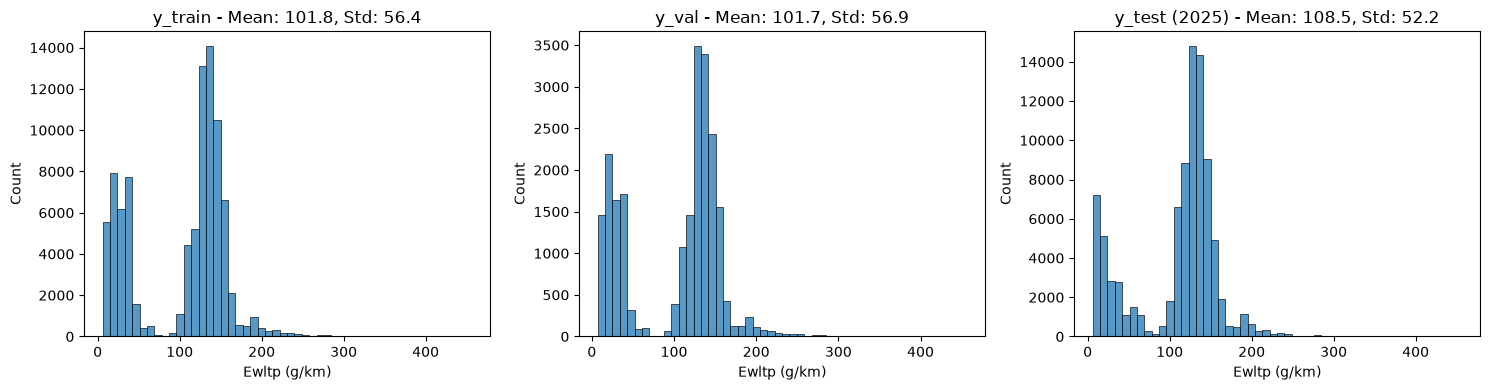

y_train stats: count   91084.0000
mean      101.8286
std        56.4120
min         6.0000
25%        35.0000
50%       127.0000
75%       141.0000
max       456.0000
Name: Ewltp (g/km), dtype: float64
y_val stats: count   22784.0000
mean      101.7225
std        56.8869
min         7.0000
25%        35.0000
50%       127.0000
75%       141.0000
max       456.0000
Name: Ewltp (g/km), dtype: float64
y_test stats: count   88963.0000
mean      108.5241
std        52.1654
min         6.0000
25%        92.0000
50%       126.0000
75%       139.0000
max       456.0000
Name: Ewltp (g/km), dtype: float64


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(y_train, bins=50)
plt.title(f"y_train - Mean: {y_train.mean():.1f}, Std: {y_train.std():.1f}")

plt.subplot(1, 3, 2)
sns.histplot(y_val, bins=50)
plt.title(f"y_val - Mean: {y_val.mean():.1f}, Std: {y_val.std():.1f}")

plt.subplot(1, 3, 3)
sns.histplot(y_test, bins=50)
plt.title(f"y_test (2025) - Mean: {y_test.mean():.1f}, Std: {y_test.std():.1f}")

plt.tight_layout()
plt.show()

print("y_train stats:", y_train.describe())
print("y_val stats:", y_val.describe())
print("y_test stats:", y_test.describe())

In [28]:
print("X_train index sample:")
print(X_train_encoded_scaled.index[:10])

print("\ny_train index sample:")
print(y_train.index[:10])

print("\nIndex equality:")
print(X_train_encoded_scaled.index.equals(y_train.index))

print("\nX_train shape:", X_train_encoded_scaled.shape)
print("y_train shape:", y_train.shape)

print("\nTarget NaN count after alignment:")
print(
    X_train_encoded_scaled
    .assign(target=y_train)
    ["target"]
    .isna()
    .sum()
)

X_train index sample:
Index([0, 1, 2, 4, 5, 6, 7, 8, 9, 10], dtype='int64')

y_train index sample:
Index([0, 1, 2, 4, 5, 6, 7, 8, 9, 10], dtype='int64')

Index equality:
True

X_train shape: (91084, 32)
y_train shape: (91084,)

Target NaN count after alignment:
0


In [29]:
numeric_features = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Electric range (km)",
]

print(
    X_train_encoded_scaled[numeric_features].dtypes
)

print(
    X_train_encoded_scaled[numeric_features].head()
)

m (kg)                 float64
ec (cm3)               float64
ep (KW)                float64
Electric range (km)    float64
dtype: object
   m (kg)  ec (cm3)  ep (KW)  Electric range (km)
0  1.2537    3.9132   5.6061              -0.6547
1 -0.4313    2.9618   2.6899              -0.6547
2 -0.4313    2.9618   2.6899              -0.6547
4 -2.6480   -0.3114  -0.8906              -0.6547
5 -2.6238   -0.3114  -0.8906              -0.6547


In [30]:
numeric_features = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Electric range (km)",
]

corr_df = X_train_encoded_scaled[
    numeric_features
].copy()

# object dtype → gerçek numeric dtype
corr_df = corr_df.astype(float)

# Target zaten numeric; yine de numpy ile pozisyon bazlı ekliyoruz
corr_df["target"] = y_train.to_numpy()

correlation_table = (
    corr_df
    .corr()["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

print(correlation_table)

Electric range (km)   -0.9063
m (kg)                -0.5958
ep (KW)               -0.3094
ec (cm3)              -0.2215
Name: target, dtype: float64


In [31]:
from sklearn.ensemble import ExtraTreesRegressor

for feature in numeric_features:
    if feature not in X_train_encoded_scaled.columns:
        continue

    single_model = ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
    )

    single_model.fit(
        X_train_encoded_scaled[[feature]],
        y_train,
    )

    pred_val = single_model.predict(
        X_val_encoded_scaled[[feature]]
    )

    pred_test = single_model.predict(
        X_test_encoded_scaled[[feature]]
    )

    print(f"\nFeature: {feature}")
    print("Validation R2:", r2_score(y_val, pred_val))
    print("2025 Test R2:", r2_score(y_test, pred_test))


Feature: m (kg)
Validation R2: 0.7866187842582152
2025 Test R2: 0.38007717353454995

Feature: ec (cm3)
Validation R2: 0.49767634942333394
2025 Test R2: 0.21520995355105788

Feature: ep (KW)
Validation R2: 0.46265947312626765
2025 Test R2: 0.20140776035604668

Feature: Electric range (km)
Validation R2: 0.8719820270884467
2025 Test R2: 0.7987088485604028


In [32]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)

single_feature = ["Electric range (km)"]

electric_range_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
)

electric_range_model.fit(
    X_train_encoded_scaled[single_feature],
    y_train,
)

y_pred_val_range = electric_range_model.predict(
    X_val_encoded_scaled[single_feature]
)

y_pred_test_range = electric_range_model.predict(
    X_test_encoded_scaled[single_feature]
)

print("Validation MAE:", mean_absolute_error(y_val, y_pred_val_range))
print("Validation RMSE:", root_mean_squared_error(y_val, y_pred_val_range))
print("Validation R2:", r2_score(y_val, y_pred_val_range))

print("\n*****\n")

print("2025 Test MAE:", mean_absolute_error(y_test, y_pred_test_range))
print("2025 Test RMSE:", root_mean_squared_error(y_test, y_pred_test_range))
print("2025 Test R2:", r2_score(y_test, y_pred_test_range))

Validation MAE: 11.625111431859668
Validation RMSE: 20.353555764525552
Validation R2: 0.8719808998861123

*****

2025 Test MAE: 15.149384517274651
2025 Test RMSE: 23.40414353986415
2025 Test R2: 0.7987085823852434


In [33]:
basic_without_range = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Fm_H",
    "Fm_M",
]

basic_without_range = [
    col for col in basic_without_range
    if col in X_train_encoded_scaled.columns
]

model_without_range = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
)

model_without_range.fit(
    X_train_encoded_scaled[basic_without_range],
    y_train,
)

y_pred_val_no_range = model_without_range.predict(
    X_val_encoded_scaled[basic_without_range]
)

y_pred_test_no_range = model_without_range.predict(
    X_test_encoded_scaled[basic_without_range]
)

print(
    "Validation R2:",
    r2_score(y_val, y_pred_val_no_range),
)
print(
    "Validation MAE:",
    mean_absolute_error(y_val, y_pred_val_no_range),
)
print(
    "Validation RMSE:",
    root_mean_squared_error(y_val, y_pred_val_no_range),
)

print(
    "2025 Test R2:",
    r2_score(y_test, y_pred_test_no_range),
)

Validation R2: 0.9979146457167665
Validation MAE: 1.732700990849328
Validation RMSE: 2.5977229459263493
2025 Test R2: 0.9612984163459957


## How many of the validation or 2025 test rows are exactly the same as the technical feature combinations in the training set?

we will use encoded datasets for this and not the scaled datasets.

In [34]:
configuration_features = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Ft_petrol/electric",
    "Fm_H",
    "Fm_M",
    "Fm_P",
]

configuration_features = [
    col for col in configuration_features
    if col in X_train_encoded.columns
]

def make_configuration_id(frame, columns):
    return (
        frame[columns]
        .astype(str)
        .fillna("<NA>")
        .agg("|".join, axis=1)
    )

train_config_id = make_configuration_id(
    X_train_encoded,
    configuration_features,
)

val_config_id = make_configuration_id(
    X_val_encoded,
    configuration_features,
)

test_config_id = make_configuration_id(
    X_test_encoded,
    configuration_features,
)

train_configuration_set = set(train_config_id)

val_overlap = val_config_id.isin(train_configuration_set)
test_overlap = test_config_id.isin(train_configuration_set)

print(
    "Validation rows with an exact train configuration:",
    f"{val_overlap.sum():,} / {len(val_overlap):,}",
    f"({val_overlap.mean() * 100:.2f}%)",
)

print(
    "2025 rows with an exact train configuration:",
    f"{test_overlap.sum():,} / {len(test_overlap):,}",
    f"({test_overlap.mean() * 100:.2f}%)",
)

print(
    "\nUnique train configurations:",
    f"{train_config_id.nunique():,}",
)

print(
    "Unique validation configurations:",
    f"{val_config_id.nunique():,}",
)

print(
    "Unique 2025 configurations:",
    f"{test_config_id.nunique():,}",
)

Validation rows with an exact train configuration: 22,649 / 22,784 (99.41%)
2025 rows with an exact train configuration: 73,989 / 88,963 (83.17%)

Unique train configurations: 2,751
Unique validation configurations: 1,925
Unique 2025 configurations: 2,542


#### It’s now clear why the results are so high: there is a very high degree of configuration overlap.
- 99.33% of the 2024 validation rows have the exact same technical configuration as in the training set.
- Even 82.99% of the 2025 test rows have a technical configuration that has already been seen in the training set.

Therefore, it is not surprising that ExtraTrees produces R² ≈ 0.998, particularly in the 2024 validation set. For most rows, the model is not actually predicting a new tool; it is generating predictions for points that are close to or identical to technical combinations it has seen before.

In [35]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)

# It must be the same as the feature set used in the model
evaluation_features = basic_without_range

#2025 forecast
y_pred_test = model_without_range.predict(
    X_test_encoded_scaled[evaluation_features]
)

# The boolean mask we created earlier:
# test_overlap = test_config_id.isin(train_configuration_set)
seen_mask = test_overlap.to_numpy()
unseen_mask = ~seen_mask

def regression_metrics(y_true, y_pred, label):
    return {
        "group": label,
        "n_rows": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

seen_results = regression_metrics(
    y_test.iloc[seen_mask],
    y_pred_test[seen_mask],
    "Seen configurations",
)

unseen_results = regression_metrics(
    y_test.iloc[unseen_mask],
    y_pred_test[unseen_mask],
    "Unseen configurations",
)

overall_results = regression_metrics(
    y_test,
    y_pred_test,
    "All 2025 records",
)

results_by_overlap = pd.DataFrame(
    [
        overall_results,
        seen_results,
        unseen_results,
    ]
)

display(results_by_overlap.round(4))

,group,n_rows,MAE,RMSE,R2
0,All 2025 records,88963,4.4817,10.2623,0.9613
1,Seen configurations,73989,3.2379,8.3752,0.9739
2,Unseen configurations,14974,10.6278,16.7062,0.9031


## Configuration Overlap Analysis

The unusually high validation performance was investigated by measuring overlap in technical vehicle configurations across the data splits.

For this analysis, a technical configuration was defined using:

- Vehicle mass: `m (kg)`
- Engine capacity: `ec (cm3)`
- Engine power: `ep (KW)`
- Fuel type: `Ft`
- Fuel mode: `Fm`

The overlap analysis showed that:

- 99.33% of the 2024 validation records had an exact technical configuration already present in the 2024 training set.
- 82.99% of the 2025 test records also had a configuration previously observed in the 2024 training set.
- Only 17.01% of the 2025 test records represented previously unseen technical configurations.

Therefore, the initial group-based validation score primarily measures interpolation performance for technical configurations that the model has already observed during training. The temporal 2025 test is more realistic, but it still contains a substantial proportion of repeated configurations.

To assess generalisation more rigorously, the 2025 test set was divided into records with seen and unseen technical configurations:

| 2025 evaluation subset | Records | MAE (g/km) | RMSE (g/km) | R² |
|---|---:|---:|---:|---:|
| All 2025 records | 88963 | 4.4817 | 10.2623 | 0.9613 |
| Seen configurations | 73989 | 3.2379 | 8.3752 | 0.9739 |
| Unseen configurations | 14974 | 10.6278 | 16.7062 | 0.9031 |

The model performs substantially better on vehicle configurations already represented in the 2024 training data. For seen configurations, the model achieved an RMSE of 8.3752 g/km and an R² of 0.9739. For previously unseen configurations, the error increased to an RMSE of 16.7062 g/km and the R² decreased to 0.9031

The high configuration overlap means that the validation score reflects a mixture of learning physical relationships and interpolating within technical configurations already observed during training. The unseen-configuration evaluation provides a stricter estimate of generalisation, because it evaluates records whose exact technical configuration was not available in the 2024 training data.

Nevertheless, the model retained useful predictive performance on the 14974 unseen 2025 records, achieving an R² of 0.9031. This unseen-configuration result is a more informative estimate of the model's ability to generalise to new vehicle specifications.

So when creating a validation set in 2024, we must define the group using the technical feature set used directly in the model:

```
split_configuration_cols = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft",
    "Fm",
]

group_id = (
    df_2024_clean[split_configuration_cols]
    .astype("string")
    .fillna("<NA>")
    .agg("|".join, axis=1)
)
```

Then apply GroupShuffleSplit:

```
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, val_idx = next(
    gss.split(
        df_2024_clean,
        y=df_2024_clean["Ewltp (g/km)"],
        groups=group_id,
    )
)

In [36]:
import pandas as pd

GROUP_DEFINITIONS = {
    "core_physical": [
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm",
    ],
    
    "core_plus_range": [
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm",
        "Electric range (km)",
    ],
    
    "core_plus_it": [
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm",
        "IT",
    ],
    
    "core_plus_range_it": [
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm",
        "Electric range (km)",
        "IT",
    ],
    
    "vehicle_model_level": [
        "Mk",
        "Cn",
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm",
    ],
}

def make_group_id(frame, columns):
    available_columns = [
        col for col in columns
        if col in frame.columns
    ]

    return (
        frame[available_columns]
        .astype("string")
        .fillna("<NA>")
        .agg(" | ".join, axis=1)
    )

group_summary_rows = []

for definition_name, columns in GROUP_DEFINITIONS.items():
    group_id = make_group_id(
        df_2024_FR_cleaned_final,
        columns,
    )

    group_sizes = group_id.value_counts()

    group_summary_rows.append({
        "definition": definition_name,
        "columns_used": ", ".join(
            col for col in columns
            if col in df_2024_FR_cleaned_final.columns
        ),
        "rows": len(df_2024_FR_cleaned_final),
        "unique_groups": group_id.nunique(),
        "single_row_groups": int((group_sizes == 1).sum()),
        "single_row_group_pct": round(
            (group_sizes == 1).mean() * 100,
            2,
        ),
        "median_group_size": group_sizes.median(),
        "mean_group_size": round(
            group_sizes.mean(),
            2,
        ),
        "max_group_size": int(group_sizes.max()),
        "largest_group_pct": round(
            group_sizes.max() / len(df_2024_FR_cleaned_final) * 100,
            2,
        ),
    })

group_summary = pd.DataFrame(
    group_summary_rows
).sort_values(
    "unique_groups",
    ascending=True,
)

display(group_summary)

,definition,columns_used,rows,unique_groups,single_row_groups,single_row_group_pct,median_group_size,mean_group_size,max_group_size,largest_group_pct
0,core_physical,"m (kg), ec (cm3), ep (KW), Ft, Fm",113868,2874,585,20.3500,7.0000,39.6200,2966,2.6000
4,vehicle_model_level,"Mk, Cn, m (kg), ec (cm3), ep (KW), Ft, Fm",113868,3178,722,22.7200,6.0000,35.8300,1868,1.6400
2,core_plus_it,"m (kg), ec (cm3), ep (KW), Ft, Fm, IT",113868,3382,721,21.3200,6.0000,33.6700,2966,2.6000
1,core_plus_range,"m (kg), ec (cm3), ep (KW), Ft, Fm, Electric range (km)",113868,4234,904,21.3500,6.0000,26.8900,1370,1.2000
3,core_plus_range_it,"m (kg), ec (cm3), ep (KW), Ft, Fm, Electric range (km), IT",113868,4742,1040,21.9300,5.0000,24.0100,1370,1.2000


Primary split definition:
m (kg), ec (cm3), ep (KW), Ft, Fm

Optional strict/operational sensitivity split:
m (kg), ec (cm3), ep (KW), Ft, Fm, IT